In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.ndimage import gaussian_filter
from matplotlib.patches import Rectangle
import matplotlib as mpl

In [2]:
mpl.rcParams['text.color'] = 'black'
mpl.rcParams['axes.labelcolor'] = 'black'
mpl.rcParams['xtick.color'] = 'black'
mpl.rcParams['ytick.color'] = 'black'

In [3]:
use_log_scale = True
remove_outliers = False
max_percentile = 99.95
smooth = True
smooth_sigma = 0.8
show_section = False
top_percentile = 5.0  # Use top 5% of solutions for robust estimates
confidence_level = 0.90  # 90% confidence level

list_datasets = [
    'results_df_utag.csv',
    'results_df_utag_c_free.csv',
    'results_df_suntag.csv',
    'results_df_alfatag.csv'
]


working_dir = Path.cwd().resolve()
project_root = next(p for p in (working_dir, *working_dir.parents)
                    if (p / 'optimization' / 'optimization.py').is_file())
path_to_optimization_data = project_root / 'optimization' / 'results_ACF'

path_to_results = project_root / 'optimization' / 'optimization_parameters'
path_to_results.mkdir(parents=True, exist_ok=True)

def round_to_sig(x):
    return float(f"{x:.4g}")


Processing dataset: results_df_utag.csv
Valid results: 6400/6400 (100.0%)
Results from top 5.0% solutions (n=320):
   Estimates: ki=0.031710, ke=3.114000, cost=1332.1793
   90% CI for ki: [0.017090, 0.047220]
   90% CI for ke: [2.101000, 4.734000]
   Estimates in CI: ki=True, ke=True


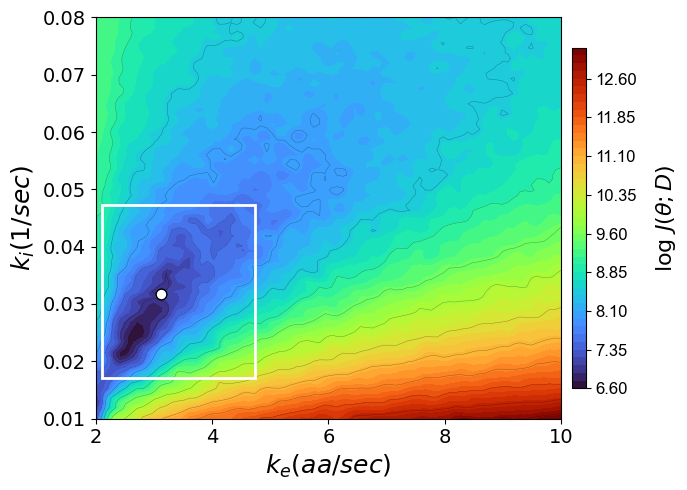

Saved: cost_surface_utag.png
------------------------------------------------------------

Processing dataset: results_df_utag_c_free.csv
Valid results: 6400/6400 (100.0%)
Results from top 5.0% solutions (n=320):
   Estimates: ki=0.063605, ke=5.342000, cost=530.2152
   90% CI for ki: [0.051605, 0.076460]
   90% CI for ke: [4.127000, 6.658000]
   Estimates in CI: ki=True, ke=True


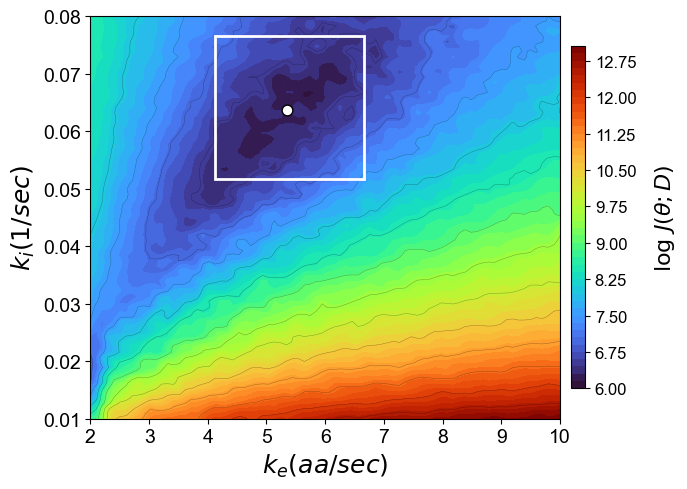

Saved: cost_surface_utag_c_free.png
------------------------------------------------------------

Processing dataset: results_df_suntag.csv
Valid results: 6400/6400 (100.0%)
Results from top 5.0% solutions (n=320):
   Estimates: ki=0.029490, ke=4.329000, cost=536.9672
   90% CI for ki: [0.017090, 0.041010]
   90% CI for ke: [2.804950, 5.954100]
   Estimates in CI: ki=True, ke=True


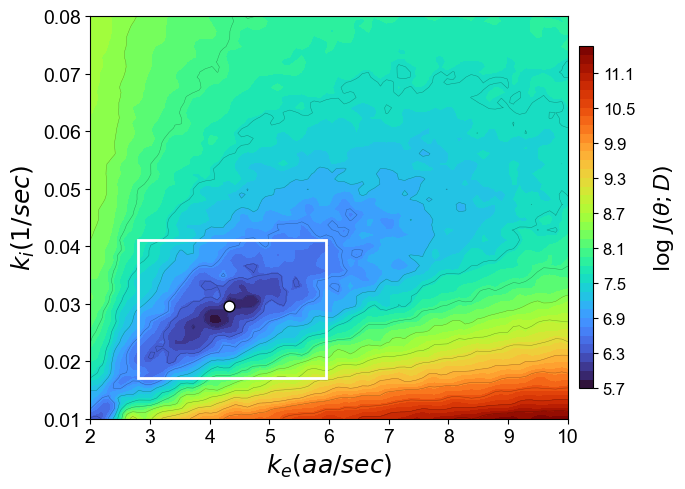

Saved: cost_surface_suntag.png
------------------------------------------------------------

Processing dataset: results_df_alfatag.csv
Valid results: 6400/6400 (100.0%)
Results from top 5.0% solutions (n=320):
   Estimates: ki=0.043670, ke=4.835000, cost=342.7505
   90% CI for ki: [0.033040, 0.054345]
   90% CI for ke: [3.924000, 5.949000]
   Estimates in CI: ki=True, ke=True


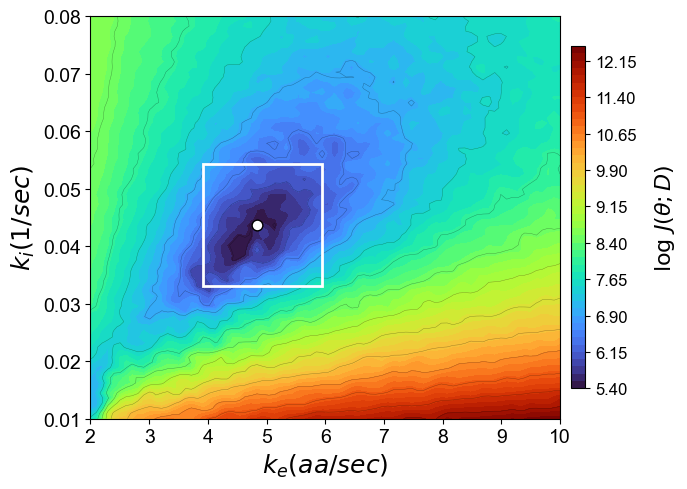

Saved: cost_surface_alfatag.png
------------------------------------------------------------


In [4]:


for i, dataset in enumerate(list_datasets):
    print(f"\nProcessing dataset: {dataset}")
    # Load and prepare data
    results_df = pd.read_csv(path_to_optimization_data.joinpath(dataset))
    results_df_copy = results_df.copy()
    results_df_copy["ki"] = results_df["ki"].apply(round_to_sig)
    results_df_copy["ke"] = results_df["ke"].apply(round_to_sig)
    
    # Clean data - remove invalid results
    valid_mask = np.isfinite(results_df_copy['cost']) & (results_df_copy['cost'] < 1e9)
    results_df_clean = results_df_copy[valid_mask].copy()
    print(f"Valid results: {len(results_df_clean)}/{len(results_df_copy)} ({100*len(results_df_clean)/len(results_df_copy):.1f}%)")
    
    if len(results_df_clean) == 0:
        print("No valid optimization results found!")
        continue
    
    # Find best solution (absolute minimum)
    best_idx = results_df_clean["cost"].idxmin()
    best_cost = results_df_clean.loc[best_idx, "cost"]
    best_ki = results_df_clean.loc[best_idx, "ki"]
    best_ke = results_df_clean.loc[best_idx, "ke"]
    
    # Calculate robust estimates from top solutions
    n_top = max(1, int(len(results_df_clean) * top_percentile / 100))
    top_solutions = results_df_clean.nsmallest(n_top, 'cost')
    
    robust_ki = np.median(top_solutions['ki'])
    robust_ke = np.median(top_solutions['ke'])
    robust_cost = np.median(top_solutions['cost'])
    
    # Calculate confidence intervals from top solutions directly
    alpha = 1 - confidence_level
    low, high = 100 * alpha/2, 100 * (1-alpha/2)
    
    ki_ci = np.percentile(top_solutions['ki'], [low, high])
    ke_ci = np.percentile(top_solutions['ke'], [low, high])
    ci_ki_low, ci_ki_high = ki_ci
    ci_ke_low, ci_ke_high = ke_ci
    
    # Print results
    print(f"Results from top {top_percentile}% solutions (n={n_top}):")
    print(f"   Estimates: ki={robust_ki:.6f}, ke={robust_ke:.6f}, cost={robust_cost:.4f}")
    print(f"   {confidence_level*100:.0f}% CI for ki: [{ki_ci[0]:.6f}, {ki_ci[1]:.6f}]")
    print(f"   {confidence_level*100:.0f}% CI for ke: [{ke_ci[0]:.6f}, {ke_ci[1]:.6f}]")
    
    # Verification
    ki_in_ci = ki_ci[0] <= robust_ki <= ki_ci[1]
    ke_in_ci = ke_ci[0] <= robust_ke <= ke_ci[1]
    print(f"   Estimates in CI: ki={ki_in_ci}, ke={ke_in_ci}")
    
    # Create pivot table for plotting
    df_pivot = results_df_clean.pivot(index='ki', columns='ke', values='cost')
    
    # Get grid values
    ki_values = df_pivot.index.values
    ke_values = df_pivot.columns.values
    NLL_grid = df_pivot.values
    X, Y = np.meshgrid(ke_values, ki_values)
    
    # Apply log scale and normalization
    if use_log_scale:
        Z = np.log(np.where(NLL_grid > 0, NLL_grid, np.nan))
        label = r"$\log\, J(\theta;D)$"
    else:
        Z = NLL_grid
        label = r"$J(\theta;\mathcal{D})$"

    # Apply outlier removal if enabled
    if remove_outliers:
        z_percentile = np.nanpercentile(Z, max_percentile)
        Z[Z > z_percentile] = np.nan
    
    # Apply smoothing if enabled
    if smooth:
        Z_smooth = gaussian_filter(Z, sigma=smooth_sigma, mode='nearest')
    else:
        Z_smooth = Z
    
    # Create normalization
    norm = mcolors.Normalize(vmin=np.nanmin(Z_smooth), vmax=np.nanmax(Z_smooth))
    
    # Get coordinates for plotting robust estimates
    robust_x = robust_ke
    robust_y = robust_ki
    
    # Create labels using robust estimates
    robust_label = f"Estimate: ki={robust_y:.3f}, ke={robust_x:.3f}"
    ci_label = f"{confidence_level*100:.0f}% CI: ki=[{ci_ki_low:.2g}, {ci_ki_high:.2g}], ke=[{ci_ke_low:.4g}, {ci_ke_high:.4g}]"
    
    # Create 2D contour plot
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.set_facecolor('white')
    plt.rcParams['font.family'] = 'Arial'
    
    # Filled contour plot
    cf = ax.contourf(
        X, Y, Z_smooth,
        levels=50,
        cmap='turbo', norm=norm
    )
    
    # Add contour lines for definition
    cs = ax.contour(
        X, Y, Z_smooth,
        levels=15,
        colors='k', linewidths=0.3, alpha=0.4
    )
    
    # Colorbar
    cbar = fig.colorbar(cf, ax=ax, shrink=0.85, aspect=25, pad=0.02)
    cbar.set_label(label, fontsize=16, fontfamily='Arial', labelpad=12)
    cbar.ax.tick_params(labelsize=12)
    
    # Plot robust estimate point (white dot)
    ax.scatter(
        robust_x, robust_y,
        color='white', edgecolor='k', s=60, marker='o',
        label=robust_label, zorder=10
    )
    
    # Plot confidence interval rectangle (white box)
    rect = Rectangle(
        (ci_ke_low, ci_ki_low),
        ci_ke_high - ci_ke_low,
        ci_ki_high - ci_ki_low,
        linewidth=2, edgecolor='white', facecolor='none',
        linestyle='-', label=ci_label, zorder=10
    )
    ax.add_patch(rect)
    
    # Styling
    ax.set_xlabel(r"$k_{e} (aa/sec)$", fontsize=18, fontfamily='Arial')
    ax.set_ylabel(r"$k_{i} (1/sec)$", fontsize=18, fontfamily='Arial')
    ax.tick_params(axis='both', labelsize=14)
    #ax.legend(loc='upper left', frameon=False, fontsize=12, labelspacing=1.2,
    #          prop={'family': 'Arial'}, labelcolor='black')
    #ax.legend(bbox_to_anchor=(0, 1.02), loc='lower left', frameon=False, fontsize=12,
    #          labelspacing=0.5, prop={'family': 'Arial'}, labelcolor='black', ncol=1)
    
    # Save plot
    dataset_name = Path(dataset).stem.replace("results_df_", "")
    plt.savefig(path_to_results.joinpath(f"cost_surface_{dataset_name}.png"), 
                dpi=300, bbox_inches='tight')
    # save plots as svgs
    plt.savefig(path_to_results.joinpath(f"cost_surface_{dataset_name}.svg"), 
                dpi=300, bbox_inches='tight')
    plt.tight_layout()
    plt.show()
    
    print(f"Saved: cost_surface_{dataset_name}.png")
    print("-" * 60)
